# Chromosome Map Exploration

This notebook builds a simple chromosome-map-style transform from the same filtered training data used in `NaFe_Dataset_Colors`. The goal is to see whether the photometry separates into structure that looks more like multiple populations than a single blob.


In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', context='notebook')

PROJECT_DIR = Path().resolve()
PROJECT_ROOT_NAME = 'spectroscopy-regression'
while PROJECT_DIR.name != PROJECT_ROOT_NAME and PROJECT_DIR != PROJECT_DIR.parent:
    PROJECT_DIR = PROJECT_DIR.parent
os.chdir(PROJECT_DIR)
PROJECT_DIR


WindowsPath('C:/Users/phucl/Research/gc/spectroscopy-regression')

In [3]:
# Load and filter the training set exactly like NaFe_Dataset_Colors
CSV_PATH = Path('data/Na_Fe_training_data.csv')

MAG_COLS = ['F275W_abs', 'F336W_abs', 'F438W_abs', 'F606W_abs', 'F814W_abs', 'Fe/H', 'age_Kruijssen']
TARGET_COL = 'Na/Fe'
RANGES = {
    'F275W_abs': (2, 10),
    'F336W_abs': (0, 6),
    'F438W_abs': (-2, 5),
    'F606W_abs': (-5, 4),
    'F814W_abs': (-5, 3),
}

df = pd.read_csv(CSV_PATH)
df = df.dropna(subset=MAG_COLS + [TARGET_COL]).copy()
for col, (lo, hi) in RANGES.items():
    df = df[(df[col] >= lo) & (df[col] <= hi)]

df['c275_336'] = df['F275W_abs'] - df['F336W_abs']
df['c336_438'] = df['F336W_abs'] - df['F438W_abs']
df['c438_606'] = df['F438W_abs'] - df['F606W_abs']
df['c606_814'] = df['F606W_abs'] - df['F814W_abs']

print('Filtered shape:', df.shape)
display(df[[TARGET_COL, 'Fe/H', 'age_Kruijssen']].describe())


Filtered shape: (245, 46)


,Na/Fe,Fe/H,age_Kruijssen
count,245.000000,245.000000,245.000000
mean,0.316266,-1.480424,11.920204
std,0.282060,0.519424,0.737192
min,-0.420000,-2.414000,10.830000
25%,0.091633,-1.817000,11.520000
50%,0.330000,-1.512000,12.030000
75%,0.528000,-1.151000,12.400000
max,1.043150,-0.398000,13.060000


In [4]:
# Fiducial helpers
def build_fiducials(frame, mag_col, color_col, n_bins=12, q_low=0.05, q_high=0.95):
    mags = frame[mag_col]
    edges = np.linspace(mags.min(), mags.max(), n_bins + 1)
    centers = []
    blue_vals = []
    red_vals = []
    for i in range(n_bins):
        lo, hi = edges[i], edges[i + 1]
        if i == n_bins - 1:
            mask = (mags >= lo) & (mags <= hi)
        else:
            mask = (mags >= lo) & (mags < hi)
        subset = frame.loc[mask, color_col].dropna()
        if len(subset) < 5:
            continue
        centers.append((lo + hi) / 2.0)
        blue_vals.append(subset.quantile(q_low))
        red_vals.append(subset.quantile(q_high))

    centers = np.asarray(centers, dtype=float)
    blue_vals = np.asarray(blue_vals, dtype=float)
    red_vals = np.asarray(red_vals, dtype=float)
    order = np.argsort(centers)
    return centers[order], blue_vals[order], red_vals[order]

def verticalize(frame, mag_col, color_col, centers, blue_vals, red_vals):
    mag = frame[mag_col].to_numpy(dtype=float)
    color = frame[color_col].to_numpy(dtype=float)
    blue = np.interp(mag, centers, blue_vals, left=blue_vals[0], right=blue_vals[-1])
    red = np.interp(mag, centers, red_vals, left=red_vals[0], right=red_vals[-1])
    width = red - blue
    width = np.where(np.abs(width) < 1e-8, np.nan, width)
    return (color - blue) / width

MAG_AXIS = 'F814W_abs'
centers_1, blue_1, red_1 = build_fiducials(df, MAG_AXIS, 'c275_336')
centers_2, blue_2, red_2 = build_fiducials(df, MAG_AXIS, 'c336_438')

df['delta_275_336'] = verticalize(df, MAG_AXIS, 'c275_336', centers_1, blue_1, red_1)
df['delta_336_438'] = verticalize(df, MAG_AXIS, 'c336_438', centers_2, blue_2, red_2)

df = df.replace([np.inf, -np.inf], np.nan).dropna(subset=['delta_275_336', 'delta_336_438'])
print('Chromosome-map rows:', len(df))


Chromosome-map rows: 245


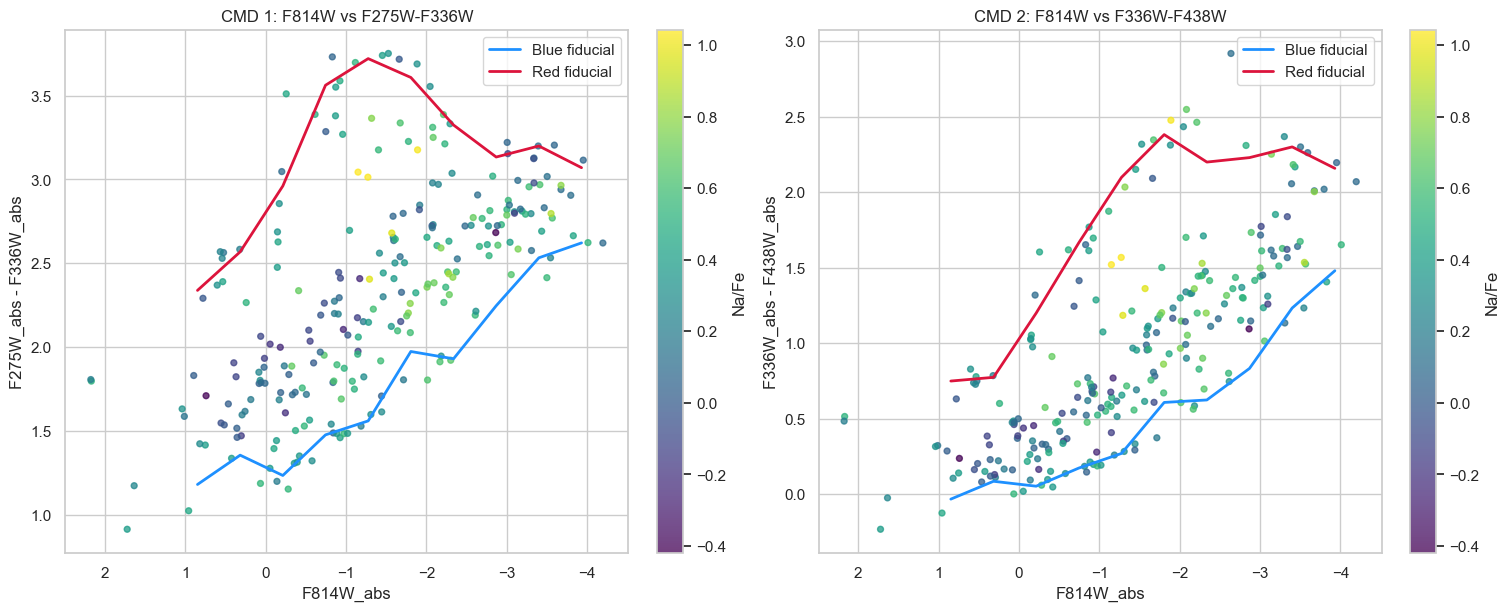

In [5]:
# Raw CMDs with fiducials overlaid
fig, axes = plt.subplots(1, 2, figsize=(15, 6), constrained_layout=True)

sc1 = axes[0].scatter(df[MAG_AXIS], df['c275_336'], c=df[TARGET_COL], s=18, cmap='viridis', alpha=0.75)
axes[0].plot(centers_1, blue_1, color='dodgerblue', lw=2, label='Blue fiducial')
axes[0].plot(centers_1, red_1, color='crimson', lw=2, label='Red fiducial')
axes[0].invert_xaxis()
axes[0].set_xlabel('F814W_abs')
axes[0].set_ylabel('F275W_abs - F336W_abs')
axes[0].set_title('CMD 1: F814W vs F275W-F336W')
axes[0].legend()
fig.colorbar(sc1, ax=axes[0], label='Na/Fe')

sc2 = axes[1].scatter(df[MAG_AXIS], df['c336_438'], c=df[TARGET_COL], s=18, cmap='viridis', alpha=0.75)
axes[1].plot(centers_2, blue_2, color='dodgerblue', lw=2, label='Blue fiducial')
axes[1].plot(centers_2, red_2, color='crimson', lw=2, label='Red fiducial')
axes[1].invert_xaxis()
axes[1].set_xlabel('F814W_abs')
axes[1].set_ylabel('F336W_abs - F438W_abs')
axes[1].set_title('CMD 2: F814W vs F336W-F438W')
axes[1].legend()
fig.colorbar(sc2, ax=axes[1], label='Na/Fe')

plt.show()


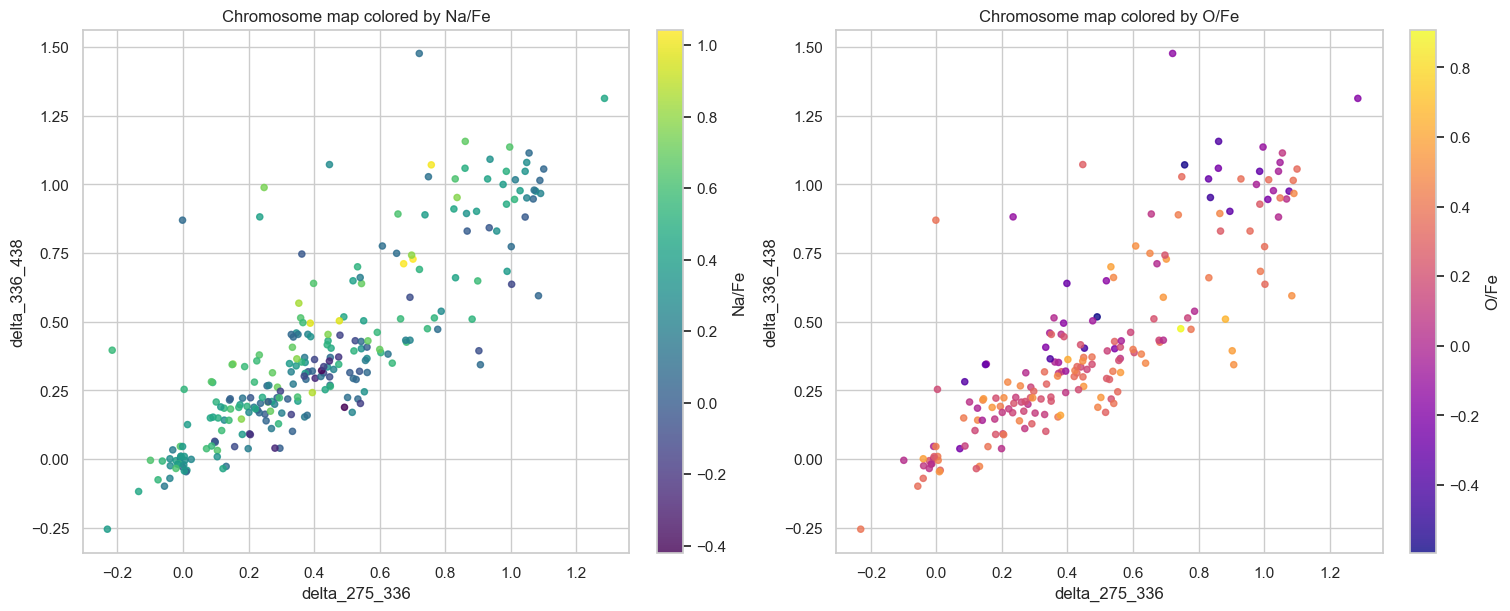

In [ ]:
# Chromosome map in verticalized coordinates
fig, axes = plt.subplots(1, 2, figsize=(15, 6), constrained_layout=True)

sc = axes[0].scatter(df['delta_275_336'], df['delta_336_438'], c=df[TARGET_COL], s=20, cmap='viridis', alpha=0.8)
axes[0].set_xlabel('delta_275_336')
axes[0].set_ylabel('delta_336_438')
axes[0].set_title('Chromosome map colored by Na/Fe')
fig.colorbar(sc, ax=axes[0], label='Na/Fe')

if 'O/Fe' in df.columns and df['O/Fe'].notna().any():
    sc = axes[1].scatter(df['delta_275_336'], df['delta_336_438'], c=df['O/Fe'], s=20, cmap='plasma', alpha=0.8)
    fig.colorbar(sc, ax=axes[1], label='O/Fe')
    axes[1].set_title('Chromosome map colored by O/Fe')
else:
    axes[1].scatter(df['delta_275_336'], df['delta_336_438'], c='steelblue', s=20, alpha=0.8)
    axes[1].set_title('Chromosome map')

axes[1].set_xlabel('delta_275_336')
axes[1].set_ylabel('delta_336_438')

plt.show()


# F275 + F438 - 2F336

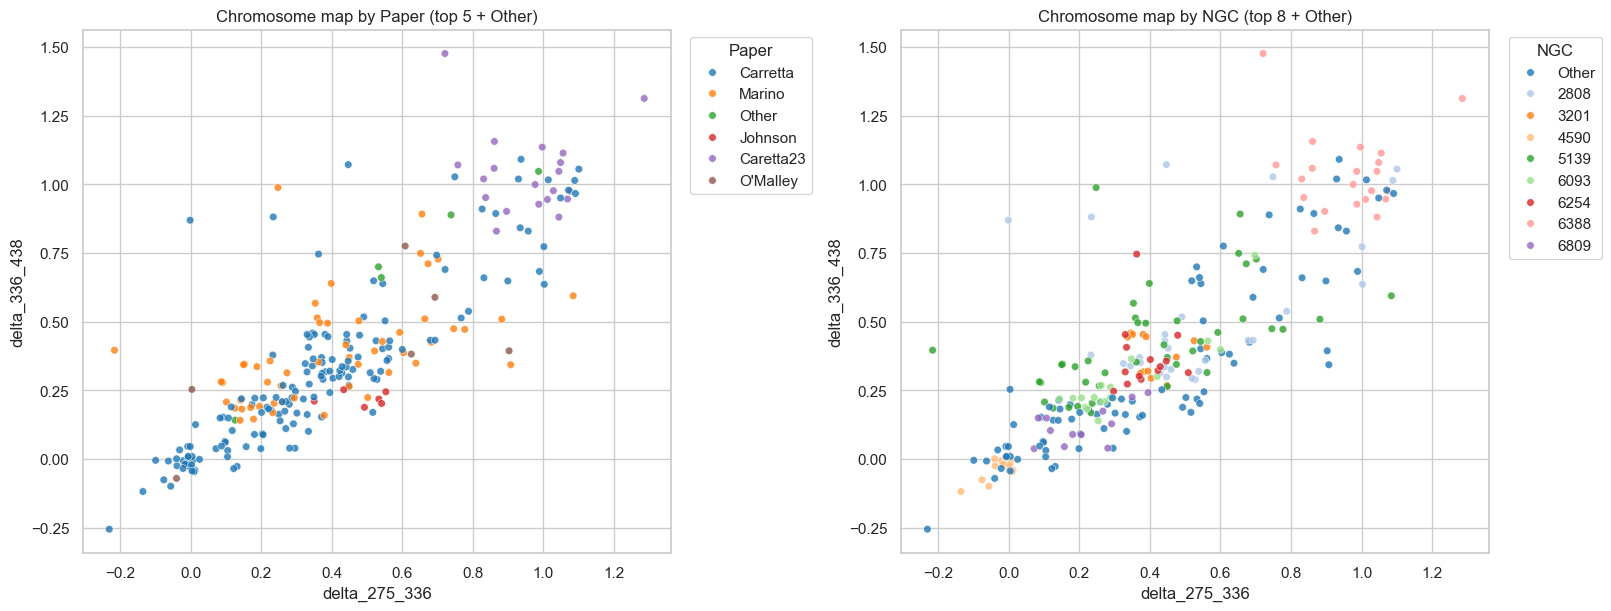

In [7]:
# Color the chromosome map by the dominant Papers and NGCs
def collapse_top_groups(series, top_n):
    counts = series.value_counts()
    keep = counts.head(top_n).index
    return series.where(series.isin(keep), other='Other')

fig, axes = plt.subplots(1, 2, figsize=(16, 6), constrained_layout=True)
paper_labels = collapse_top_groups(df['Paper'], top_n=5) if 'Paper' in df.columns else pd.Series(['Other'] * len(df), index=df.index)
ngc_labels = collapse_top_groups(df['NGC'], top_n=8) if 'NGC' in df.columns else pd.Series(['Other'] * len(df), index=df.index)

sns.scatterplot(data=df, x='delta_275_336', y='delta_336_438', hue=paper_labels, palette='tab10', s=30, alpha=0.8, ax=axes[0])
axes[0].set_title('Chromosome map by Paper (top 5 + Other)')
axes[0].legend(title='Paper', bbox_to_anchor=(1.02, 1), loc='upper left')

sns.scatterplot(data=df, x='delta_275_336', y='delta_336_438', hue=ngc_labels, palette='tab20', s=30, alpha=0.8, ax=axes[1])
axes[1].set_title('Chromosome map by NGC (top 8 + Other)')
axes[1].legend(title='NGC', bbox_to_anchor=(1.02, 1), loc='upper left')

axes[0].set_xlabel('delta_275_336')
axes[0].set_ylabel('delta_336_438')
axes[1].set_xlabel('delta_275_336')
axes[1].set_ylabel('delta_336_438')

plt.show()


In [8]:
# Quick summary of how informative the chromosome-map coordinates are
corr_cols = ['delta_275_336', 'delta_336_438', TARGET_COL]
if 'O/Fe' in df.columns:
    corr_cols.append('O/Fe')
display(df[corr_cols].corr(numeric_only=True))

print('If the chromosome map shows separated branches or clear color gradients, it is worth using these coordinates as inputs for regression.')
print('If it is still a blob, try a different magnitude axis, a tighter RGB selection, or a better fiducial construction.')


,delta_275_336,delta_336_438,Na/Fe,O/Fe
delta_275_336,1.000000,0.839213,-0.053953,-0.079417
delta_336_438,0.839213,1.000000,0.118563,-0.274403
Na/Fe,-0.053953,0.118563,1.000000,-0.451430
O/Fe,-0.079417,-0.274403,-0.451430,1.000000


If the chromosome map shows separated branches or clear color gradients, it is worth using these coordinates as inputs for regression.
If it is still a blob, try a different magnitude axis, a tighter RGB selection, or a better fiducial construction.


Rows after cleaning: 1333
F275W_abs    float64
F336W_abs    float64
F435W_abs    float64
F814W_abs    float64
dtype: object
Rows after RGB cut: 1087
Rows used for chromosome map: 1087


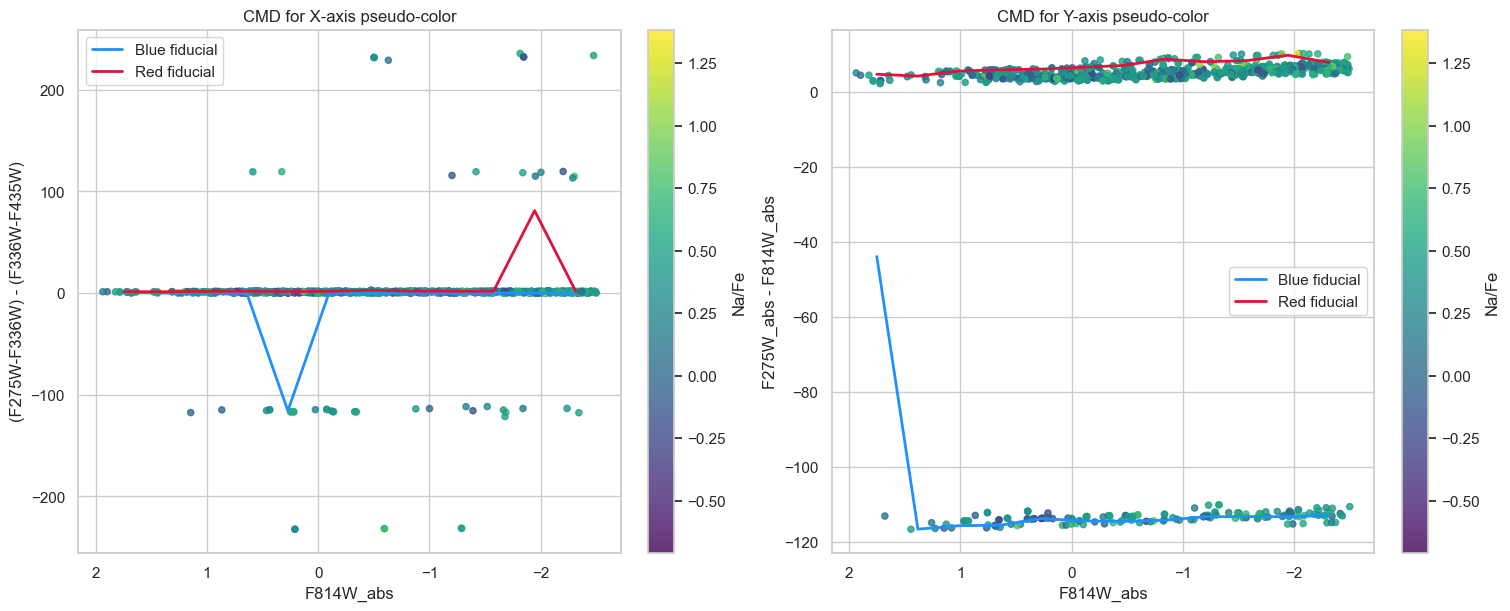

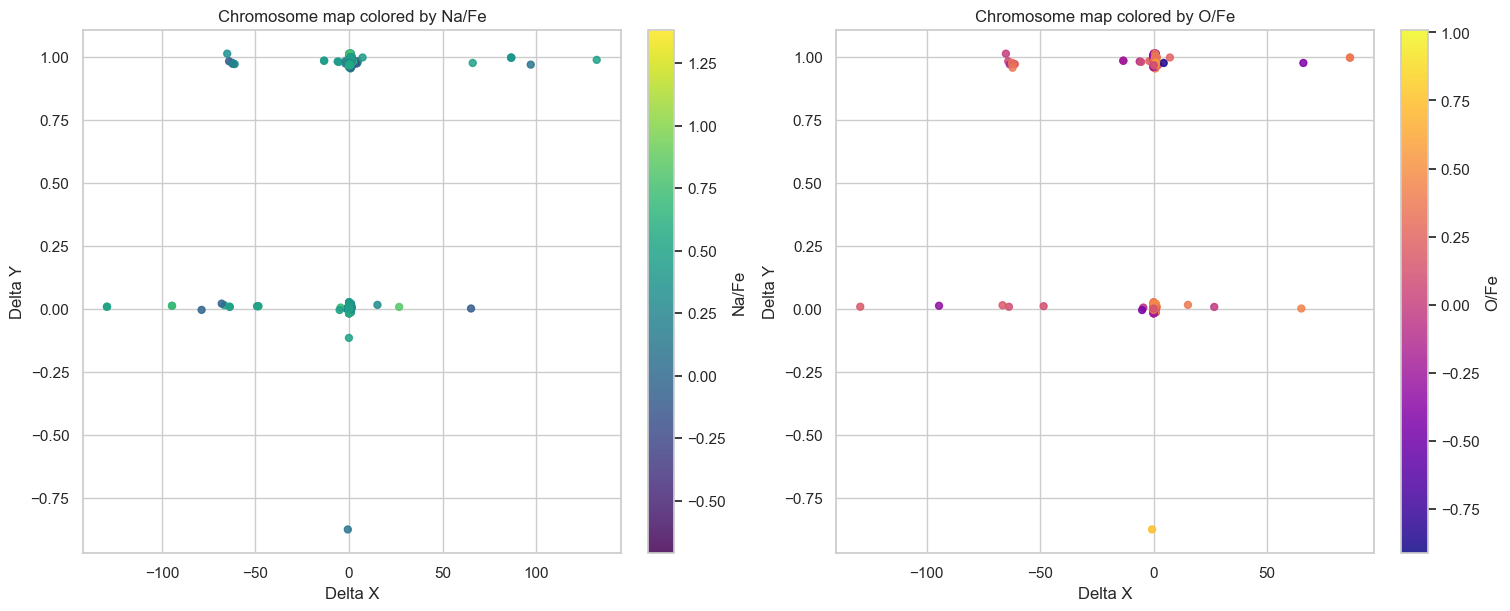

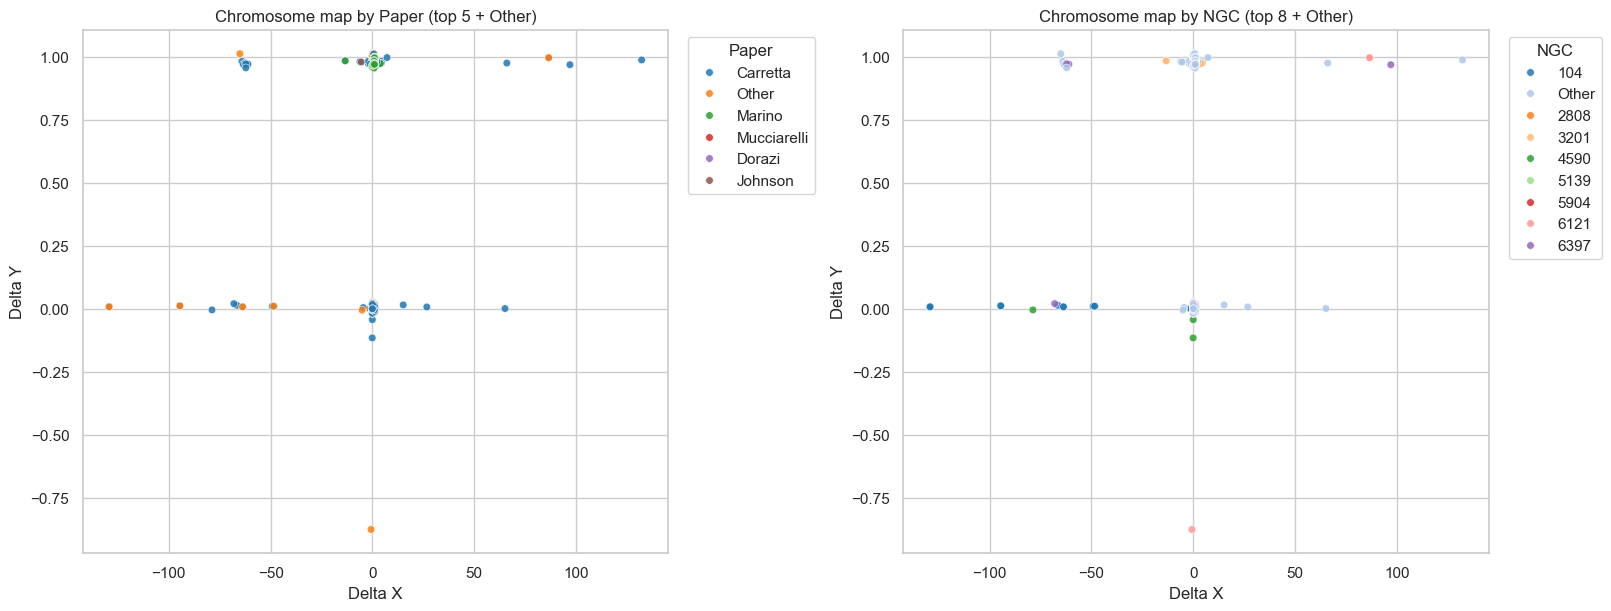

,delta_x,delta_y,Na/Fe,O/Fe
delta_x,1.000000,0.153431,-0.027040,0.040758
delta_y,0.153431,1.000000,0.002731,0.020246
Na/Fe,-0.027040,0.002731,1.000000,-0.484061
O/Fe,0.040758,0.020246,-0.484061,1.000000


In [3]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

# Set project root
PROJECT_DIR = Path().resolve()
PROJECT_ROOT_NAME = "spectroscopy-regression"
while PROJECT_DIR.name != PROJECT_ROOT_NAME and PROJECT_DIR != PROJECT_DIR.parent:
    PROJECT_DIR = PROJECT_DIR.parent
os.chdir(PROJECT_DIR)

# Load data
csv_path = Path("data/NGC_combi.csv")
df = pd.read_csv(csv_path)

# Clean column names
df.columns = [c.strip() for c in df.columns]

# Columns needed for chromosome-map axes
needed_cols = [
    "F275W_abs",
    "F336W_abs",
    "F435W_abs",
    "F814W_abs",
]

# Convert needed columns to numeric first
for col in needed_cols + ["Na/Fe", "O/Fe"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Drop rows missing any axis column
df = df.dropna(subset=needed_cols).copy()

# Build chromosome-map pseudo-colors
# X-axis pseudo-color:
# C_F275W,F336W,F435W = (m_F275W - m_F336W) - (m_F336W - m_F435W)
df["C_275_336_435"] = (df["F275W_abs"] - df["F336W_abs"]) - (df["F336W_abs"] - df["F435W_abs"])

# Y-axis pseudo-color:
# F275W - F814W style pseudo-color
df["C_275_814"] = df["F275W_abs"] - df["F814W_abs"]

# Optional abundance columns may still contain NaN
has_nafe = "Na/Fe" in df.columns and df["Na/Fe"].notna().any()
has_ofe = "O/Fe" in df.columns and df["O/Fe"].notna().any()

print("Rows after cleaning:", len(df))
print(df[needed_cols].dtypes)

# ------------------------------------------------------------
# RGB selection
# ------------------------------------------------------------
# Simple RGB selection. Adjust if you want tighter/lower/higher RGB limits.
rgb = df[(df["F814W_abs"] > -2.5) & (df["F814W_abs"] < 2.0)].copy()
print("Rows after RGB cut:", len(rgb))

# ------------------------------------------------------------
# Fiducial helpers
# ------------------------------------------------------------
def build_fiducials(frame, mag_col, color_col, n_bins=12, q_low=0.05, q_high=0.95):
    mags = frame[mag_col].to_numpy(dtype=float)
    colors = frame[color_col].to_numpy(dtype=float)

    edges = np.linspace(np.nanmin(mags), np.nanmax(mags), n_bins + 1)

    centers = []
    blue_vals = []
    red_vals = []

    for i in range(n_bins):
        lo, hi = edges[i], edges[i + 1]
        if i == n_bins - 1:
            mask = (mags >= lo) & (mags <= hi)
        else:
            mask = (mags >= lo) & (mags < hi)

        vals = colors[mask]
        vals = vals[np.isfinite(vals)]

        if len(vals) < 5:
            continue

        centers.append((lo + hi) / 2.0)
        blue_vals.append(np.quantile(vals, q_low))
        red_vals.append(np.quantile(vals, q_high))

    centers = np.asarray(centers, dtype=float)
    blue_vals = np.asarray(blue_vals, dtype=float)
    red_vals = np.asarray(red_vals, dtype=float)

    order = np.argsort(centers)
    return centers[order], blue_vals[order], red_vals[order]

def verticalize(frame, mag_col, color_col, centers, blue_vals, red_vals):
    mag = frame[mag_col].to_numpy(dtype=float)
    color = frame[color_col].to_numpy(dtype=float)

    blue = np.interp(mag, centers, blue_vals, left=blue_vals[0], right=blue_vals[-1])
    red = np.interp(mag, centers, red_vals, left=red_vals[0], right=red_vals[-1])

    width = red - blue
    width = np.where(np.abs(width) < 1e-8, np.nan, width)

    return (color - blue) / width

# Use F814W as the magnitude axis
mag_axis = "F814W_abs"

# Fiducials for the X-axis pseudo-color
centers_x, blue_x, red_x = build_fiducials(rgb, mag_axis, "C_275_336_435", n_bins=12)

# Fiducials for the Y-axis pseudo-color
centers_y, blue_y, red_y = build_fiducials(rgb, mag_axis, "C_275_814", n_bins=12)

# Verticalize
rgb["delta_x"] = verticalize(rgb, mag_axis, "C_275_336_435", centers_x, blue_x, red_x)
rgb["delta_y"] = verticalize(rgb, mag_axis, "C_275_814", centers_y, blue_y, red_y)

# Clean infinities / missing values
rgb = rgb.replace([np.inf, -np.inf], np.nan).dropna(subset=["delta_x", "delta_y"]).copy()
print("Rows used for chromosome map:", len(rgb))

# ------------------------------------------------------------
# Raw CMDs with fiducials
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(15, 6), constrained_layout=True)

if has_nafe:
    color_values = rgb["Na/Fe"]
else:
    color_values = "steelblue"

sc1 = axes[0].scatter(rgb["F814W_abs"], rgb["C_275_336_435"], c=color_values, s=20, cmap="viridis", alpha=0.8)
axes[0].plot(centers_x, blue_x, color="dodgerblue", lw=2, label="Blue fiducial")
axes[0].plot(centers_x, red_x, color="crimson", lw=2, label="Red fiducial")
axes[0].invert_xaxis()
axes[0].set_xlabel("F814W_abs")
axes[0].set_ylabel("(F275W-F336W) - (F336W-F435W)")
axes[0].set_title("CMD for X-axis pseudo-color")
axes[0].legend()

if has_nafe:
    fig.colorbar(sc1, ax=axes[0], label="Na/Fe")

sc2 = axes[1].scatter(rgb["F814W_abs"], rgb["C_275_814"], c=color_values, s=20, cmap="viridis", alpha=0.8)
axes[1].plot(centers_y, blue_y, color="dodgerblue", lw=2, label="Blue fiducial")
axes[1].plot(centers_y, red_y, color="crimson", lw=2, label="Red fiducial")
axes[1].invert_xaxis()
axes[1].set_xlabel("F814W_abs")
axes[1].set_ylabel("F275W_abs - F814W_abs")
axes[1].set_title("CMD for Y-axis pseudo-color")
axes[1].legend()

if has_nafe:
    fig.colorbar(sc2, ax=axes[1], label="Na/Fe")

plt.show()

# ------------------------------------------------------------
# Chromosome map
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(15, 6), constrained_layout=True)

if has_nafe:
    sc = axes[0].scatter(rgb["delta_x"], rgb["delta_y"], c=rgb["Na/Fe"], s=25, cmap="viridis", alpha=0.85)
    fig.colorbar(sc, ax=axes[0], label="Na/Fe")
    axes[0].set_title("Chromosome map colored by Na/Fe")
else:
    axes[0].scatter(rgb["delta_x"], rgb["delta_y"], s=25, alpha=0.85, color="steelblue")
    axes[0].set_title("Chromosome map")

axes[0].set_xlabel("Delta X")
axes[0].set_ylabel("Delta Y")

if has_ofe:
    sc = axes[1].scatter(rgb["delta_x"], rgb["delta_y"], c=rgb["O/Fe"], s=25, cmap="plasma", alpha=0.85)
    fig.colorbar(sc, ax=axes[1], label="O/Fe")
    axes[1].set_title("Chromosome map colored by O/Fe")
else:
    axes[1].scatter(rgb["delta_x"], rgb["delta_y"], s=25, alpha=0.85, color="steelblue")
    axes[1].set_title("Chromosome map")

axes[1].set_xlabel("Delta X")
axes[1].set_ylabel("Delta Y")

plt.show()

# ------------------------------------------------------------
# Color by Paper and NGC
# ------------------------------------------------------------
def collapse_top_groups(series, top_n):
    counts = series.value_counts()
    keep = counts.head(top_n).index
    return series.where(series.isin(keep), other="Other")

fig, axes = plt.subplots(1, 2, figsize=(16, 6), constrained_layout=True)

if "Paper" in rgb.columns:
    paper_labels = collapse_top_groups(rgb["Paper"], top_n=5)
    sns.scatterplot(
        data=rgb,
        x="delta_x",
        y="delta_y",
        hue=paper_labels,
        palette="tab10",
        s=30,
        alpha=0.85,
        ax=axes[0],
    )
    axes[0].legend(title="Paper", bbox_to_anchor=(1.02, 1), loc="upper left")
else:
    axes[0].scatter(rgb["delta_x"], rgb["delta_y"], s=30, alpha=0.85, color="steelblue")

axes[0].set_title("Chromosome map by Paper (top 5 + Other)")
axes[0].set_xlabel("Delta X")
axes[0].set_ylabel("Delta Y")

if "NGC" in rgb.columns:
    ngc_labels = collapse_top_groups(rgb["NGC"], top_n=8)
    sns.scatterplot(
        data=rgb,
        x="delta_x",
        y="delta_y",
        hue=ngc_labels,
        palette="tab20",
        s=30,
        alpha=0.85,
        ax=axes[1],
    )
    axes[1].legend(title="NGC", bbox_to_anchor=(1.02, 1), loc="upper left")
else:
    axes[1].scatter(rgb["delta_x"], rgb["delta_y"], s=30, alpha=0.85, color="steelblue")

axes[1].set_title("Chromosome map by NGC (top 8 + Other)")
axes[1].set_xlabel("Delta X")
axes[1].set_ylabel("Delta Y")

plt.show()

# ------------------------------------------------------------
# Quick correlations
# ------------------------------------------------------------
corr_cols = ["delta_x", "delta_y"]
if has_nafe:
    corr_cols.append("Na/Fe")
if has_ofe:
    corr_cols.append("O/Fe")

display(rgb[corr_cols].corr(numeric_only=True))